# Slovo RSL: training and evaluation comparison

This report compares the 256-unit Slovo GRU with the 128-unit run. Both use the
same cached features and signer-aware split. Results below come from saved
configuration, epoch and evaluation files. Run All redraws the report; it does
not train or evaluate either model. The ASL notebooks are separate and unchanged.

The 128-unit retry completed with early stopping. Its training log records
three skipped batches across the run; AMP recovery allowed training to continue.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt


def find_project_root():
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / 'pyproject.toml').is_file():
            return folder
    raise FileNotFoundError('Run this notebook from the project or one of its subfolders.')


def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))


def print_table(headers, rows):
    rows = [[str(value) for value in row] for row in rows]
    widths = [max(len(str(header)), *(len(row[i]) for row in rows)) for i, header in enumerate(headers)]
    print(' | '.join(str(value).ljust(widths[i]) for i, value in enumerate(headers)))
    print('-+-'.join('-' * width for width in widths))
    for row in rows:
        print(' | '.join(value.ljust(widths[i]) for i, value in enumerate(row)))


def pct(value):
    return f'{100 * value:.2f}%'


ROOT = find_project_root()
RUN_SPECS = {
    'GRU-256': {
        'directory': 'models/slovo-gru-v1',
        'evaluation': 'data/evaluations/slovo-gru-v1-report.json',
        'color': '#2878b5',
    },
    'GRU-128': {
        'directory': 'models/slovo-gru-128-v1-nonfinitegradfix',
        'evaluation': 'data/evaluations/slovo-gru-128-v1-nonfinitegradfix-report.json',
        'color': '#e49320',
    },
}
REPORTS_AVAILABLE = all(
    (ROOT / spec['directory'] / 'config.json').is_file()
    and (ROOT / spec['evaluation']).is_file()
    for spec in RUN_SPECS.values()
)
RUNS = {}
CACHE = {}
SPLITS = {}
if REPORTS_AVAILABLE:
    for name, spec in RUN_SPECS.items():
        folder = ROOT / spec['directory']
        history = [read_json(path) for path in sorted(folder.glob('epoch-*.json'))]
        chosen = min(history, key=lambda row: row['val']['loss'])
        config = read_json(folder / 'config.json')
        status = read_json(folder / 'status.json')
        report = read_json(ROOT / spec['evaluation'])
        assert report['status'] == 'complete'
        assert report['checkpoint_epoch'] == chosen['epoch']
        RUNS[name] = {
            **spec, 'folder': folder, 'config': config, 'status': status,
            'history': history, 'selected': chosen, 'report': report,
        }
    CACHE = read_json(ROOT / 'data/training/slovo-hands-128-v1/manifest.json')
    assert len({run['report']['cache_id'] for run in RUNS.values()}) == 1
    assert all(run['report']['cache_id'] == CACHE['cache_id'] for run in RUNS.values())
    SPLITS = RUNS['GRU-256']['report']['split_metadata']
    print('Both reports use cache:', CACHE['cache_id'])
else:
    print('No completed Slovo run reports found; training cells are available below.')

plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2,
    'figure.constrained_layout.use': True,
})
print('Project:', ROOT)
print('Report-only view; no model weights are loaded.')


Project: D:\Sign Language
Both reports use cache: be929dc07d9cc254e88db63885db3c36c56c10c161199527b0ec862d458fb161
Read-only comparison; no model weights are loaded.


## Model design and opt-in training

This notebook defines the two-layer, unidirectional GRU and its training loop.
Each frame has 132 hands-only features and sequences are packed by their true
lengths before the final hidden state feeds a 1,000-class linear head. Training
uses AdamW, CUDA mixed precision, gradient clipping, validation-loss checkpoint
selection and early stopping. It reads only the signer-grouped train and
validation cache partitions; the test arrays are reserved for later evaluation.

The training switch below is `False` by default. Set it to `True` only when you
intend to start a run. Prepare the cache first with `scripts/slovo.py prepare`.


In [ ]:
import hashlib
import math
import time
from datetime import datetime, timezone

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, Dataset

from sign_language.dataset import write_json
from sign_language.slovo_dataset import INPUT_SIZE, MAX_FRAMES, SCHEMA

CACHE_ROOT = ROOT / 'data/training/slovo-hands-128-v1'
OUTPUT_ROOT = ROOT / 'models/slovo-gru-v1'
EPOCHS = 50
BATCH_SIZE = 64
LOADER_WORKERS = 2
PATIENCE = 10
HIDDEN_SIZE = 256
RUN_TRAINING = False
SMOKE_TRAINING = False


class SlovoTrainingDataset(Dataset):
    """Memory-map one cache split and skip clips with no landmarks."""
    def __init__(self, root, split):
        self.root = Path(root)
        self.split = split
        self.features = None
        self.lengths = np.load(self.root / f'{split}-lengths.npy', mmap_mode='r')
        self.targets = None
        self.valid_indices = np.flatnonzero(self.lengths > 0)

    def __len__(self):
        return len(self.valid_indices)

    def __getstate__(self):
        return {**self.__dict__, 'features': None, 'lengths': None, 'targets': None}

    def __getitem__(self, index):
        if self.features is None:
            self.features = np.load(self.root / f'{self.split}-features.npy', mmap_mode='r')
            self.lengths = np.load(self.root / f'{self.split}-lengths.npy', mmap_mode='r')
            self.targets = np.load(self.root / f'{self.split}-targets.npy', mmap_mode='r')
        index = int(self.valid_indices[index])
        return (
            torch.from_numpy(np.array(self.features[index], dtype=np.float32)),
            int(self.lengths[index]),
            int(self.targets[index]),
        )


class SlovoGRU(nn.Module):
    """Packed two-layer GRU with dropout and a jointly trained linear head."""
    def __init__(self, input_size=INPUT_SIZE, hidden_size=256, layers=2,
                 classes=1000, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(
            input_size, hidden_size, num_layers=layers, batch_first=True,
            dropout=dropout if layers > 1 else 0,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, classes)

    def forward(self, frames, lengths):
        packed = pack_padded_sequence(
            frames, lengths.cpu(), batch_first=True, enforce_sorted=False,
        )
        _, hidden = self.gru(packed)
        return self.classifier(self.dropout(hidden[-1]))


def validate_slovo_cache(cache):
    cache = Path(cache)
    manifest = json.loads((cache / 'manifest.json').read_text(encoding='utf-8'))
    status = json.loads((cache / 'status.json').read_text(encoding='utf-8'))
    labels = json.loads((cache / 'labels.json').read_text(encoding='utf-8'))
    if (manifest.get('dataset') != 'Slovo Russian Sign Language'
            or status.get('status') != 'complete'
            or status.get('cache_id') != manifest.get('cache_id')
            or manifest.get('identity', {}).get('feature_schema') != SCHEMA
            or manifest.get('input_size') != INPUT_SIZE
            or manifest.get('max_frames') != MAX_FRAMES
            or labels != manifest.get('labels')):
        raise ValueError('Incomplete or incompatible Slovo feature cache')
    return manifest, labels


In [ ]:
def clip_finite_gradients(parameters, max_norm):
    """Clip finite FP32 gradients with a double-precision norm reduction."""
    parameters = [parameter for parameter in parameters if parameter.grad is not None]
    if not parameters:
        return 0.0
    norm_squared = torch.zeros((), dtype=torch.float64, device=parameters[0].grad.device)
    for parameter in parameters:
        norm_squared += parameter.grad.detach().to(torch.float64).square().sum()
    total_norm = float(torch.sqrt(norm_squared).item())
    if not math.isfinite(total_norm):
        raise FloatingPointError('Gradient norm is nonfinite')
    coefficient = min(1.0, max_norm / (total_norm + 1e-6))
    if coefficient < 1.0:
        for parameter in parameters:
            parameter.grad.mul_(coefficient)
    return total_norm


def atomic_checkpoint(path, state):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(state, temporary)
    temporary.replace(path)


def training_pass(model, loader, optimizer=None, scaler=None, max_batches=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    samples = top1 = top5 = steps = 0
    skipped_batches = 0
    began = time.monotonic()
    for frames, lengths, targets in loader:
        frames = frames.cuda(non_blocking=True)
        targets = targets.cuda(non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training), torch.autocast('cuda', dtype=torch.float16):
            logits = model(frames, lengths)
            loss = nn.functional.cross_entropy(logits, targets)
        if not torch.isfinite(logits).all() or not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite Slovo output or loss')
        if training:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            gradients_finite = all(
                bool(torch.isfinite(parameter.grad).all().item())
                for parameter in model.parameters() if parameter.grad is not None
            )
            if not gradients_finite:
                scaler.step(optimizer)
                scaler.update()
                skipped_batches += 1
            else:
                clip_finite_gradients(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
        batch = len(targets)
        loss_sum += float(loss.detach()) * batch
        top1 += int((logits.argmax(1) == targets).sum())
        top5 += int((logits.topk(min(5, logits.shape[1]), dim=1).indices
                     == targets[:, None]).any(1).sum())
        samples += batch
        steps += 1
        if max_batches is not None and steps >= max_batches:
            break
    if samples == 0:
        raise ValueError('Empty Slovo train/validation loader')
    if training and skipped_batches / steps > 0.05:
        raise FloatingPointError(
            f'Skipped {skipped_batches}/{steps} batches due to nonfinite gradients'
        )
    torch.cuda.synchronize()
    metrics = {
        'loss': loss_sum / samples, 'top1': top1 / samples, 'top5': top5 / samples,
        'samples': samples, 'batches': steps, 'seconds': time.monotonic() - began,
    }
    if training:
        metrics['skipped_batches'] = skipped_batches
        metrics['amp_scale'] = float(scaler.get_scale())
    return metrics


def run_slovo_training(cache, output, *, epochs=50, batch_size=64, workers=2,
                       patience=10, hidden_size=256, smoke=False):
    """Train on cache train/validation only; never inspect test arrays."""
    cache, output = Path(cache), Path(output)
    if output.exists():
        raise ValueError(f'Training output already exists: {output}')
    if epochs < 1 or batch_size < 1 or workers < 0 or patience < 1 or hidden_size < 1:
        raise ValueError('Invalid Slovo training configuration')
    if smoke:
        epochs = 1
    manifest, labels = validate_slovo_cache(cache)
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA unavailable; Slovo training requires a GPU')
    torch.set_num_threads(2)
    torch.backends.cudnn.enabled = False
    torch.manual_seed(42)
    np.random.seed(42)
    model_config = {
        'input_size': INPUT_SIZE, 'hidden_size': hidden_size, 'layers': 2,
        'classes': len(labels), 'dropout': 0.3,
    }
    config = {
        'dataset': 'slovo', 'architecture': 'gru', 'model': model_config,
        'cache_id': manifest['cache_id'], 'preprocessing': SCHEMA,
        'max_frames': MAX_FRAMES, 'epochs': epochs, 'batch_size': batch_size,
        'loader_workers': workers, 'patience': patience, 'seed': 42,
        'optimizer': 'AdamW', 'learning_rate': 0.001, 'weight_decay': 0.0001,
        'validation_selection': 'minimum signer-grouped validation cross-entropy',
        'test_evaluated_during_training': False, 'augmentation': 'none',
        'training_notebook': 'notebooks/03_slovo_training_and_evaluation.ipynb',
        'source_sha256': {
            'slovo_dataset.py': hashlib.sha256(
                (ROOT / 'src/sign_language/slovo_dataset.py').read_bytes()).hexdigest(),
            'gru_model.py': hashlib.sha256(
                (ROOT / 'src/sign_language/gru_model.py').read_bytes()).hexdigest(),
        },
        'torch': str(torch.__version__), 'smoke': smoke,
    }
    output.mkdir(parents=True)
    write_json(output / 'config.json', config)
    write_json(output / 'labels.json', labels)
    model = SlovoGRU(**model_config).cuda()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config['learning_rate'], weight_decay=config['weight_decay'],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=3,
    )
    scaler = torch.amp.GradScaler('cuda')
    generator = torch.Generator().manual_seed(42)
    loaders = {
        split: DataLoader(
            SlovoTrainingDataset(cache, split), batch_size=batch_size,
            shuffle=(split == 'train'), num_workers=workers, pin_memory=True,
            persistent_workers=workers > 0,
            generator=generator if split == 'train' else None,
            **({'prefetch_factor': 2} if workers else {}),
        )
        for split in ('train', 'val')
    }
    best_loss, stale, completed_epochs = math.inf, 0, 0
    write_json(output / 'status.json', {
        'status': 'running', 'epoch': 0, 'epochs': epochs,
        'cache_id': manifest['cache_id'], 'test_evaluated': False,
    })
    try:
        for epoch in range(1, epochs + 1):
            if stale >= patience:
                break
            began = time.monotonic()
            train_metrics = training_pass(
                model, loaders['train'], optimizer, scaler,
                max_batches=8 if smoke else None,
            )
            val_metrics = training_pass(
                model, loaders['val'], max_batches=4 if smoke else None,
            )
            scheduler.step(val_metrics['loss'])
            improved = val_metrics['loss'] < best_loss
            if improved:
                best_loss, stale = val_metrics['loss'], 0
            else:
                stale += 1
            completed_epochs = epoch
            record = {
                'epoch': epoch, 'train': train_metrics, 'val': val_metrics,
                'learning_rate': optimizer.param_groups[0]['lr'],
                'seconds': time.monotonic() - began,
            }
            write_json(output / f'epoch-{epoch:03d}.json', record)
            checkpoint = {
                'config': config, 'model': model.state_dict(), 'labels': labels,
                'epoch': epoch, 'metrics': record, 'best_val_loss': best_loss,
            }
            atomic_checkpoint(output / 'last.pt', checkpoint)
            if improved:
                atomic_checkpoint(output / 'best.pt', checkpoint)
            write_json(output / 'status.json', {
                'status': 'running', 'epoch': epoch, 'epochs': epochs,
                'best_val_loss': best_loss, 'stale_epochs': stale,
                'last_epoch': record, 'cache_id': manifest['cache_id'],
                'test_evaluated': False,
            })
        status = {
            'status': 'smoke_complete' if smoke else 'completed',
            'epoch': completed_epochs, 'epochs': epochs,
            'stop_reason': 'early_stopping' if stale >= patience else 'epoch_budget_reached',
            'best_val_loss': best_loss, 'stale_epochs': stale,
            'cache_id': manifest['cache_id'], 'test_evaluated': False,
        }
        write_json(output / 'status.json', status)
        return status
    except BaseException as exc:
        write_json(output / 'status.json', {
            'status': 'failed', 'error': str(exc), 'cache_id': manifest['cache_id'],
            'test_evaluated': False,
        })
        raise


In [ ]:
if RUN_TRAINING:
    TRAINING_STATUS = run_slovo_training(
        CACHE_ROOT, OUTPUT_ROOT, epochs=EPOCHS, batch_size=BATCH_SIZE,
        workers=LOADER_WORKERS, patience=PATIENCE,
        hidden_size=HIDDEN_SIZE, smoke=SMOKE_TRAINING,
    )
    print(TRAINING_STATUS)
else:
    print('Training disabled. Set RUN_TRAINING = True to start an intentional run.')


## 1. Run summary

The two runs differ in GRU hidden size; their other saved training settings
match. The selected checkpoint for each run is the epoch with lowest validation
cross-entropy. The 128-unit retry completed 47 epochs and selected epoch 37.

In [2]:
if REPORTS_AVAILABLE:
    usable = CACHE['usable_counts']
    rows = []
    for name, run in RUNS.items():
        cfg, status, selected = run['config'], run['status'], run['selected']
        progress = (f"completed {len(run['history'])} epochs" if status['status'] == 'completed'
                    else f"{status['status']}; {len(run['history'])} complete epoch records")
        has_skip_log = all('skipped_batches' in row['train'] for row in run['history'])
        skipped = (sum(row['train']['skipped_batches'] for row in run['history'])
                   if has_skip_log else 'not logged')
        rows.append([
            name, cfg['model']['hidden_size'], cfg['model']['layers'], progress,
            selected['epoch'], pct(selected['val']['top1']), f"{selected['val']['loss']:.4f}", skipped,
        ])
    print_table(
        ['Run', 'Hidden', 'Layers', 'Training status', 'Selected epoch', 'Val top-1', 'Val loss', 'Skipped batches'],
        rows,
    )
    print()
    print_table(
        ['Partition', 'Usable clips', 'Classes represented'],
        [
            ['Train', usable['train'], len(CACHE['labels'])],
            ['Validation', usable['val'], SPLITS['validation']['validation_classes']],
            ['Official flag test', RUNS['GRU-256']['report']['official_flag_test']['samples'], RUNS['GRU-256']['report']['official_flag_test']['supported_classes']],
            ['Unseen-signer subset', RUNS['GRU-256']['report']['unseen_signer_test']['samples'], RUNS['GRU-256']['report']['unseen_signer_test']['supported_classes']],
        ],
    )
    print()
    for name, run in RUNS.items():
        cfg = run['config']
        print(f"{name}: dropout={cfg['model']['dropout']}, lr={cfg['learning_rate']}, weight_decay={cfg['weight_decay']}, batch={cfg['batch_size']}")
    run128 = RUNS['GRU-128']
    if run128['status']['status'] == 'completed':
        records = run128['history']
        print(f"GRU-128 AMP recovery: {sum(row['train'].get('skipped_batches', 0) for row in records)} skipped batches across {len(records)} epochs; final scale={records[-1]['train'].get('amp_scale', 'not recorded')}.")
else:
    print('No saved evaluation report; skipped this report-only cell.')


Run     | Hidden | Layers | Training status     | Selected epoch | Val top-1 | Val loss | Skipped batches
--------+--------+--------+---------------------+----------------+-----------+----------+----------------
GRU-256 | 256    | 2      | completed 26 epochs | 16             | 30.16%    | 3.2445   | not logged     
GRU-128 | 128    | 2      | completed 47 epochs | 37             | 28.50%    | 3.2934   | 3              

Partition            | Usable clips | Classes represented
---------------------+--------------+--------------------
Train                | 10901        | 1000               
Validation           | 4091         | 1000               
Official flag test   | 4998         | 1000               
Unseen-signer subset | 1609         | 639                

GRU-256: dropout=0.3, lr=0.001, weight_decay=0.0001, batch=64
GRU-128: dropout=0.3, lr=0.001, weight_decay=0.0001, batch=64
GRU-128 AMP recovery: 3 skipped batches across 47 epochs; final scale=65536.0.


## 2. Learning curves

Solid lines show training metrics and dashed lines show validation metrics.
Each dotted marker shows the checkpoint selected by validation loss. The
128-unit retry stopped after 47 epochs by early stopping, selecting epoch 37.

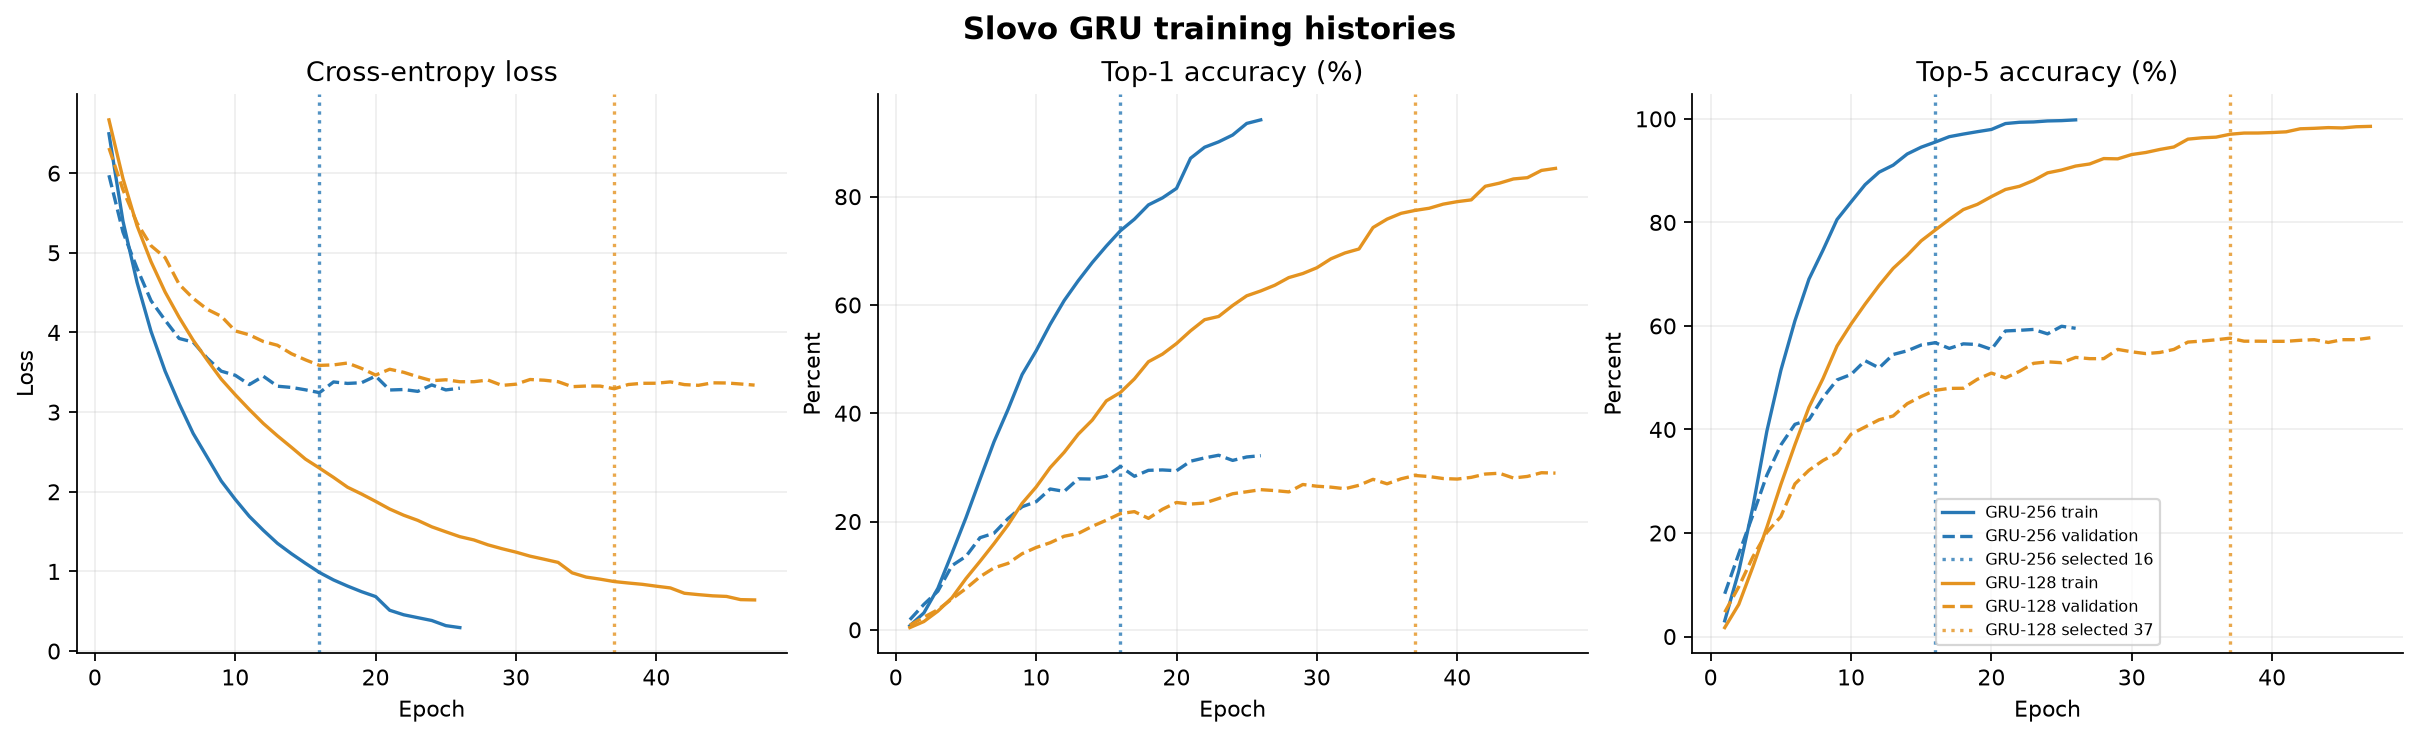

In [3]:
if REPORTS_AVAILABLE:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    metrics = [
        ('loss', 'Cross-entropy loss'),
        ('top1', 'Top-1 accuracy (%)'),
        ('top5', 'Top-5 accuracy (%)'),
    ]
    for name, run in RUNS.items():
        history = run['history']
        epochs = [row['epoch'] for row in history]
        color = run['color']
        for ax, (key, title) in zip(axes, metrics):
            scale = 100 if key != 'loss' else 1
            ax.plot(epochs, [row['train'][key] * scale for row in history],
                    color=color, label=f'{name} train')
            ax.plot(epochs, [row['val'][key] * scale for row in history],
                    color=color, linestyle='--', label=f'{name} validation')
            ax.axvline(run['selected']['epoch'], color=color, linestyle=':', alpha=0.8,
                       label=f"{name} selected {run['selected']['epoch']}")
            ax.set(title=title, xlabel='Epoch')
    axes[1].set_ylabel('Percent')
    axes[2].set_ylabel('Percent')
    axes[0].set_ylabel('Loss')
    axes[-1].legend(fontsize=7, loc='best')
    fig.suptitle('Slovo GRU training histories', fontsize=14, fontweight='bold')
    plt.show()
else:
    print('No saved evaluation report; skipped this report-only cell.')


## 3. Frozen test comparison

The 128-unit and 256-unit checkpoints were evaluated on the same official test
clips and the same unseen-signer subset. Top-1 and top-5 count clips equally.
Macro F1 gives each class equal weight; the supported-class score excludes
classes with no test examples, while the all-label score includes all 1,000
labels (unsupported classes contribute zero).

In [4]:
if REPORTS_AVAILABLE:
    protocols = [
        ('Official flag test', 'official_flag_test'),
        ('Unseen-signer subset', 'unseen_signer_test'),
    ]
    metric_rows = []
    for name, run in RUNS.items():
        for label, key in protocols:
            result = run['report'][key]
            metric_rows.append([
                name, label, result['samples'], f"{result['supported_classes']}/{result['total_classes']}",
                pct(result['top1']), pct(result['top5']),
                pct(result['macro_f1_supported_classes']), pct(result['macro_f1_all_classes']),
                f"{result['loss']:.4f}",
            ])
    print_table(
        ['Run', 'Evaluation', 'Clips', 'Labels', 'Top-1', 'Top-5', 'Macro F1 (supported)', 'Macro F1 (all)', 'Loss'],
        metric_rows,
    )
    print()
    for label, key in protocols:
        a = RUNS['GRU-256']['report'][key]
        b = RUNS['GRU-128']['report'][key]
        print(f"{label}: GRU-128 minus GRU-256 top-1 = {100 * (b['top1'] - a['top1']):+.2f} percentage points")
else:
    print('No saved evaluation report; skipped this report-only cell.')


Run     | Evaluation           | Clips | Labels    | Top-1  | Top-5  | Macro F1 (supported) | Macro F1 (all) | Loss  
--------+----------------------+-------+-----------+--------+--------+----------------------+----------------+-------
GRU-256 | Official flag test   | 4998  | 1000/1000 | 28.55% | 56.92% | 26.83%               | 26.83%         | 3.3060
GRU-256 | Unseen-signer subset | 1609  | 639/1000  | 25.11% | 54.32% | 24.89%               | 15.90%         | 3.5541
GRU-128 | Official flag test   | 4998  | 1000/1000 | 28.61% | 57.92% | 27.26%               | 27.26%         | 3.3196
GRU-128 | Unseen-signer subset | 1609  | 639/1000  | 24.98% | 54.75% | 24.77%               | 15.83%         | 3.5639

Official flag test: GRU-128 minus GRU-256 top-1 = +0.06 percentage points
Unseen-signer subset: GRU-128 minus GRU-256 top-1 = -0.12 percentage points


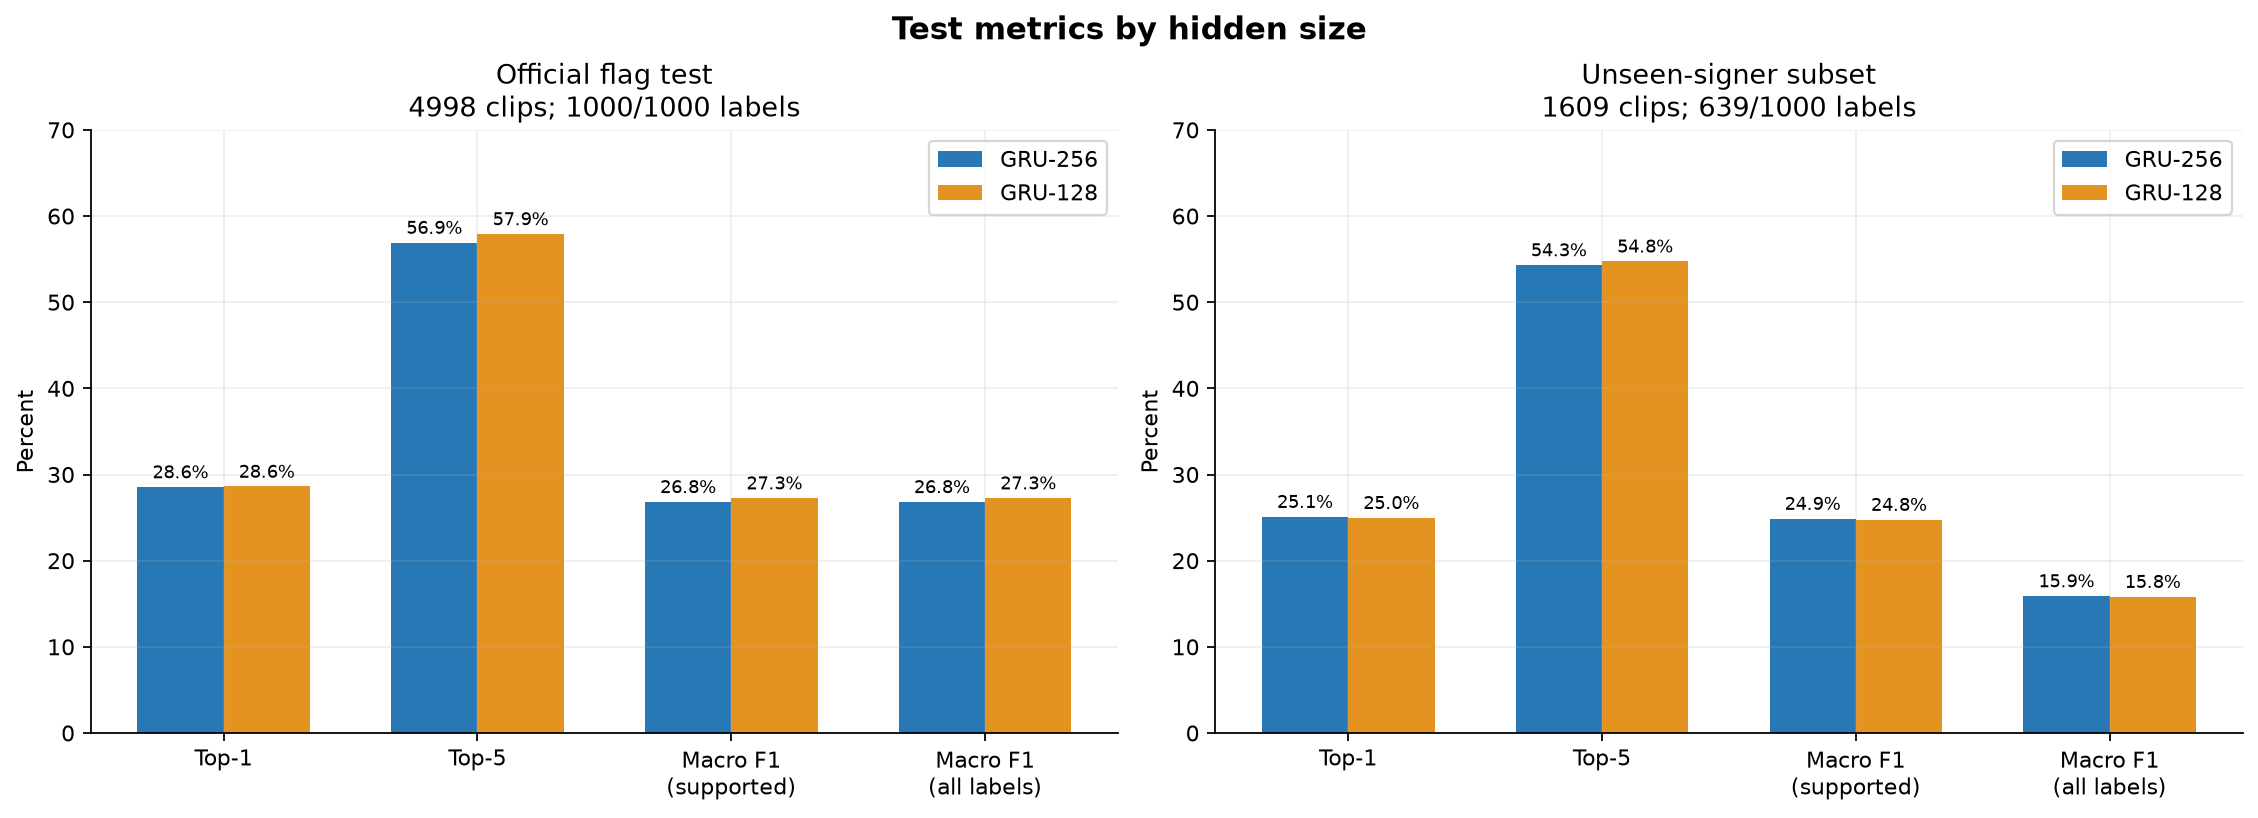

In [5]:
if REPORTS_AVAILABLE:
    metric_specs = [
        ('top1', 'Top-1'), ('top5', 'Top-5'),
        ('macro_f1_supported_classes', 'Macro F1\n(supported)'),
        ('macro_f1_all_classes', 'Macro F1\n(all labels)'),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(len(metric_specs))
    width = 0.34
    for ax, (protocol_name, protocol_key) in zip(axes, protocols):
        for offset, name in [(-width / 2, 'GRU-256'), (width / 2, 'GRU-128')]:
            report = RUNS[name]['report'][protocol_key]
            values = [100 * report[key] for key, _ in metric_specs]
            bars = ax.bar(x + offset, values, width, label=name, color=RUNS[name]['color'])
            ax.bar_label(bars, fmt='%.1f%%', padding=2, fontsize=8)
        test = RUNS['GRU-256']['report'][protocol_key]
        ax.set(xticks=x, xticklabels=[label for _, label in metric_specs], ylabel='Percent', ylim=(0, 70))
        ax.set_title(f"{protocol_name}\n{test['samples']} clips; {test['supported_classes']}/{test['total_classes']} labels")
        ax.legend()
    fig.suptitle('Test metrics by hidden size', fontsize=14, fontweight='bold')
    plt.show()
else:
    print('No saved evaluation report; skipped this report-only cell.')


## 4. Split protocol and interpretation

Both reports reference the same feature cache, so these are comparable views of
the same data split. The official flag test has signer overlap with training;
the unseen-signer result is stricter but covers fewer classes and is a subset
of the official test, not an independent second test.

The 128-unit report evaluates its saved epoch-37 checkpoint. Training
completed normally after 47 of the configured 50 epochs, with zero skipped
batches. The run used the same learning rate, dropout, weight decay, batch size
and seed as the 256-unit run; hidden size was the intended change.

In [6]:
if REPORTS_AVAILABLE:
    validation = SPLITS['validation']
    unseen = SPLITS['unseen_signer_test']
    print_table(
        ['Split detail', 'Value'],
        [
            ['Official split source', SPLITS['official_split']],
            ['Validation method', validation['method']],
            ['Validation signer groups (train / val)', f"{validation['training_signers']} / {validation['validation_signers']}"],
            ['Validation classes', f"{validation['validation_classes']} / {validation['total_classes']}"],
            ['Signer IDs shared by official train and test', SPLITS['shared_official_train_test_signers']],
            ['Unseen-signer test signers', unseen['signers']],
            ['Unseen-signer class coverage', f"{unseen['classes']} / {RUNS['GRU-256']['config']['model']['classes']}"],
            ['Cache identity same for both runs', RUNS['GRU-256']['report']['cache_id'] == RUNS['GRU-128']['report']['cache_id']],
        ],
    )
    print()
    for name, run in RUNS.items():
        print(f"{name}: training status={run['status']['status']}; selected epoch={run['selected']['epoch']}; evaluated checkpoint epoch={run['report']['checkpoint_epoch']}.")
else:
    print('No saved evaluation report; skipped this report-only cell.')


Split detail                                 | Value                                                       
---------------------------------------------+-------------------------------------------------------------
Official split source                        | annotations.csv train boolean preserved                     
Validation method                            | deterministic signer-group holdout; randomized greedy search
Validation signer groups (train / val)       | 105 / 7                                                     
Validation classes                           | 1000 / 1000                                                 
Signer IDs shared by official train and test | 92                                                          
Unseen-signer test signers                   | 82                                                          
Unseen-signer class coverage                 | 639 / 1000                                                  
Cache identity same for both

## 5. Takeaway and provenance

The completed 128-unit model is close to the 256-unit model. It is slightly
higher on official-test top-1, top-5 and macro F1, while the 256-unit model is
slightly higher on unseen-signer top-1 and macro F1. These small differences on
one fixed split do not establish a clear winner; repeated signer-grouped
validation would help determine whether either setting is more robust. Both
checkpoints use the same validation-loss selection rule. Keep the test sets
frozen while choosing future settings.

Run All reads the files listed below and redraws tables and plots. It does not
load model weights, train, run inference or modify reports.